# Rutas de tiempo mínimo para vehículos eléctricos en Uruguay

**Proyecto final — Algoritmos Avanzados de Búsqueda y Optimización (UCU)**

Un vehículo eléctrico tiene que ir de un origen $s$ a un destino $t$. La batería no alcanza
para cualquier tramo y recargar lleva tiempo, así que el camino más corto **no siempre es el
más rápido**: a veces conviene desviarse hasta un cargador rápido aunque haya uno lento más
cerca.

Este notebook implementa y compara los dos enfoques del informe:

| | Enfoque | Formulación | Tipo |
|---|---|---|---|
| 1 | **Dijkstra** | camino mínimo sobre $G=(V,E)$ | exacto |
| 2 | **Voraz** | secuencia de paradas, una por vez | heurístico |

---
## Paso 0 — Dependencias

In [38]:
import importlib.util, subprocess, sys

faltan = [p for p in ("numpy", "matplotlib", "pandas") if importlib.util.find_spec(p) is None]
if faltan:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *faltan])

In [39]:
%matplotlib inline
import hashlib, heapq, json, math, re, time, urllib.request
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from math import inf
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carpetas del proyecto (se crean solas)
DATOS = Path("datos");        DATOS.mkdir(exist_ok=True)
RESULTADOS = Path("resultados"); RESULTADOS.mkdir(exist_ok=True)


def guardar(nombre):
    # Guarda la figura actual en resultados/ (para usarla en el informe)
    plt.savefig(RESULTADOS / f"{nombre}.png", bbox_inches="tight", dpi=200)

print("Listo.")

Listo.


---
## Paso 1 — Datos: la red de carga

Se combinan **dos fuentes reales y públicas**:

1. **Mapa oficial del MIEM / UTE** (Google My Maps, formato KML). Es la fuente "oficial", pero
   está desactualizado: tiene la red inicial ("Ruta eléctrica"), con muy pocos cargadores rápidos.
2. **OpenStreetMap**: los cargadores que carga la comunidad (`amenity=charging_station`), que
   completan lo que le falta al mapa del MIEM.

Si un cargador aparece en las dos, se queda el del MIEM. Las dos fuentes se descargan la primera
vez y se guardan en `datos/`; para actualizarlas, borrá esos archivos y volvé a correr.

In [40]:
URL_KML = ("https://www.google.com/maps/d/kml?"
           "mid=1KFRobnOPGp6_IjpEWCijy-e1BGs-pzth&forcekml=1")
ARCHIVO_KML = DATOS / "red_carga.kml"


def descargar(url, destino, timeout=60):
    pedido = urllib.request.Request(url, headers={"User-Agent": "algabo-ucu/1.0"})
    with urllib.request.urlopen(pedido, timeout=timeout) as r:
        destino.write_bytes(r.read())


if ARCHIVO_KML.exists():
    print(f"Usando la copia local: {ARCHIVO_KML}  ({ARCHIVO_KML.stat().st_size/1e6:.1f} MB)")
else:
    print("Descargando el mapa de la red de carga...")
    descargar(URL_KML, ARCHIVO_KML)
    print(f"Guardado en {ARCHIVO_KML}  ({ARCHIVO_KML.stat().st_size/1e6:.1f} MB)")

Usando la copia local: datos\red_carga.kml  (1.7 MB)


### Cómo se lee cada cargador

Cada cargador del mapa es un `<Placemark>` con:

- `<coordinates>`: `longitud,latitud,altura` (la fuente confiable de la ubicación);
- `<ExtendedData>`: campos como `Direccion`, `Ciudad`, `Departamento`, `Potencia` y `Tipo`.

El tipo de corriente está **dentro del texto** del campo `Tipo`, por ejemplo
`1 conector CC CHAdeMO - 50 kW con cable`. Por eso:

- si algún conector dice **CC** (o DC), el punto es de **corriente continua** (carga rápida) y
  su potencia es la mayor de sus conectores CC;
- si no, es de **corriente alterna** (carga lenta) y su potencia es la mayor que aparezca.

Los datos tienen formatos variados (`7,4 kw`, `4x43 kw`, `kW`/`kw`), así que la lectura es
tolerante. También se descartan, si se quiere, los cargadores de uso exclusivo para taxis.

In [41]:
EXCLUIR_SOLO_TAXIS = True     # True: no usar cargadores reservados a taxis

_KW = re.compile(r"(\d+(?:[.,]\d+)?)\s*kw", re.I)
_TROZO_CC = re.compile(r"\b(CC|DC)\b", re.I)


def _local(tag):
    return tag.rsplit("}", 1)[-1]


def _numero(s):
    return float(s.replace(",", "."))


def interpretar_tipo(tipo, potencia=""):
    # Devuelve ("CC" o "CA", potencia en kW) a partir de los textos del mapa.
    trozos = re.split(r"[;/\n]|\s{2,}|,(?!\d)|\by\b", tipo or "")
    kw_cc = [_numero(m) for t in trozos if _TROZO_CC.search(t) for m in _KW.findall(t)]
    if _TROZO_CC.search(tipo or ""):
        return "CC", max(kw_cc) if kw_cc else 50.0
    kws = [_numero(m) for m in _KW.findall(tipo or "")]
    kws += [_numero(m) for m in _KW.findall(potencia or "")]
    return "CA", max(kws) if kws else 22.0


def leer_cargadores(ruta_kml, excluir_taxis=EXCLUIR_SOLO_TAXIS):
    raiz = ET.parse(ruta_kml).getroot()
    filas = []
    for pm in raiz.iter():
        if _local(pm.tag) != "Placemark":
            continue
        coord = next((e.text for e in pm.iter() if _local(e.tag) == "coordinates"), None)
        es_punto = any(_local(e.tag) == "Point" for e in pm.iter())
        if not es_punto or not coord:
            continue                                   # rutas dibujadas, etc.
        lon, lat = (float(v) for v in coord.strip().split(",")[:2])
        datos = {}
        for d in pm.iter():
            if _local(d.tag) == "Data":
                v = next((e.text for e in d if _local(e.tag) == "value"), "") or ""
                datos[d.get("name", "").strip()] = v.strip()
        nombre = next((e.text for e in pm if _local(e.tag) == "name"), "") or ""
        taxis = datos.get("Uso exclusivo para taxis", "").lower()
        if excluir_taxis and taxis.startswith(("si", "sí", "yes", "true")):
            continue
        tipo, kw = interpretar_tipo(datos.get("Tipo", ""), datos.get("Potencia", ""))
        filas.append({"nombre": nombre.strip(), "ciudad": datos.get("Ciudad", ""),
                      "departamento": datos.get("Departamento", ""),
                      "lat": lat, "lon": lon, "tipo": tipo, "kw": kw})
    df = pd.DataFrame(filas)
    # Dos marcadores en el mismo lugar cuentan como un solo punto de carga (el más potente)
    df = (df.sort_values("kw", ascending=False)
            .drop_duplicates(subset=["lat", "lon"]).reset_index(drop=True))
    return df

**Verificación** de la lectura con ejemplos con el mismo formato que el mapa.

In [42]:
assert interpretar_tipo("1 conector CC CHAdeMO - 50 kW con cable") == ("CC", 50.0)
assert interpretar_tipo("2 conectores AC Tipo 2 - 22 kW sin cable") == ("CA", 22.0)
assert interpretar_tipo("1 conector AC Tipo 2 - 43 kW, 1 conector CC CCS2 - 60 kW") == ("CC", 60.0)
assert interpretar_tipo("", "7,4 kw") == ("CA", 7.4)
assert interpretar_tipo("", "4x43 kw") == ("CA", 43.0)
print("La lectura de tipos y potencias funciona.")

La lectura de tipos y potencias funciona.


In [43]:
cargadores_miem = leer_cargadores(ARCHIVO_KML).assign(fuente="MIEM")

print(f"Puntos de carga del mapa del MIEM: {len(cargadores_miem)}")
display(cargadores_miem.groupby("tipo")["kw"]
        .agg(cantidad="count", kW_min="min", kW_mediana="median", kW_max="max"))

Puntos de carga del mapa del MIEM: 76


,cantidad,kW_min,kW_mediana,kW_max
tipo,,,,
CA,69,7.4,22.0,43.0
CC,7,50.0,50.0,50.0


### OpenStreetMap

Se le pide a la API **Overpass** de OpenStreetMap todos los cargadores dentro de Uruguay. Cada
uno trae etiquetas (*tags*) como:

- `socket:chademo`, `socket:type2_combo` (CCS2) → conectores de **corriente continua**;
- `socket:type2`, `socket:type1` → conectores de **corriente alterna**;
- `socket:<tipo>:output = "50 kW"` → potencia de ese conector.

Con eso se decide igual que con el MIEM: si tiene algún conector de continua, es **CC** con la
mayor potencia de continua; si no, es **CA**. Cuando falta la potencia se usa un valor típico
(50 kW en CC, 22 kW en CA). Se descartan los de acceso privado.

In [44]:
import urllib.parse

OVERPASS = ["https://overpass-api.de/api/interpreter",
            "https://overpass.kumi.systems/api/interpreter"]
CONSULTA_OSM = '''
[out:json][timeout:120];
area["ISO3166-1"="UY"][admin_level=2]->.uy;
nwr["amenity"="charging_station"](area.uy);
out center tags;
'''
ARCHIVO_OSM = DATOS / "osm_cargadores.json"
EXCLUIR_PRIVADOS = True       # True: no usar cargadores con access=private / no

if ARCHIVO_OSM.exists():
    print(f"Usando la copia local: {ARCHIVO_OSM}")
else:
    datos_post = urllib.parse.urlencode({"data": CONSULTA_OSM}).encode()
    for url in OVERPASS:
        try:
            print(f"Pidiendo los cargadores a {url} ...")
            pedido = urllib.request.Request(url, data=datos_post,
                                            headers={"User-Agent": "algabo-ucu/1.0"})
            with urllib.request.urlopen(pedido, timeout=180) as r:
                ARCHIVO_OSM.write_bytes(r.read())
            break
        except Exception as e:
            print(f"  falló ({e}); pruebo con el siguiente servidor")
    else:
        raise RuntimeError("No se pudo descargar OpenStreetMap. Revisá la conexión y reintentá.")
osm_crudo = json.loads(ARCHIVO_OSM.read_text(encoding="utf-8"))["elements"]
print(f"Elementos de OpenStreetMap: {len(osm_crudo)}")

Usando la copia local: datos\osm_cargadores.json
Elementos de OpenStreetMap: 42


In [45]:
SOCKETS_CC = ("chademo", "type2_combo", "type1_combo", "ccs", "gb_dc", "tesla_supercharger")
SOCKETS_CA = ("type2", "type2_cable", "type1", "schuko", "cee_blue", "type3c", "gb_ac")


def _potencia_osm(texto):
    # "50 kW" -> 50 ; "22000 W" -> 22 ; "7.4" -> 7.4 ; vacío -> None
    if not texto:
        return None
    nums = re.findall(r"(\d+(?:[.,]\d+)?)\s*(kw|w)?", texto, re.I)
    vals = []
    for n, u in nums:
        v = _numero(n)
        if u.lower() == "w" or (not u and v > 1000):
            v /= 1000
        vals.append(v)
    return max(vals) if vals else None


def interpretar_osm(tags):
    # Devuelve ("CC" o "CA", potencia en kW) a partir de las etiquetas de OSM
    def hay(s):
        v = tags.get(f"socket:{s}", "")
        return v not in ("", "no", "0")

    def kw_de(sockets):
        return [k for s in sockets if (k := _potencia_osm(tags.get(f"socket:{s}:output"))) is not None]

    general = [_potencia_osm(tags.get(k)) for k in ("charging_station:output", "maxpower")]
    general = [g for g in general if g is not None]
    if any(hay(s) for s in SOCKETS_CC):
        kws = kw_de(SOCKETS_CC) or [g for g in general if g >= 25]
        return "CC", max(kws) if kws else 50.0
    kws = kw_de(SOCKETS_CA) or general
    if kws and max(kws) >= 40 and not any(hay(s) for s in SOCKETS_CA):
        return "CC", max(kws)          # sin enchufes cargados pero con potencia de carga rápida
    return "CA", min(max(kws), 43.0) if kws else 22.0


def leer_osm(elementos, excluir_privados=EXCLUIR_PRIVADOS):
    filas = []
    for el in elementos:
        tags = el.get("tags", {})
        lat = el.get("lat", el.get("center", {}).get("lat"))
        lon = el.get("lon", el.get("center", {}).get("lon"))
        if lat is None or lon is None:
            continue
        if excluir_privados and tags.get("access", "") in ("private", "no"):
            continue
        tipo, kw = interpretar_osm(tags)
        filas.append({"nombre": tags.get("name") or tags.get("operator") or f"OSM {el['id']}",
                      "ciudad": tags.get("addr:city", ""), "departamento": "",
                      "lat": float(lat), "lon": float(lon), "tipo": tipo, "kw": kw,
                      "fuente": "OpenStreetMap"})
    return pd.DataFrame(filas, columns=["nombre", "ciudad", "departamento", "lat", "lon",
                                        "tipo", "kw", "fuente"])

**Verificación** de la lectura de OpenStreetMap con etiquetas como las reales.

In [46]:
assert interpretar_osm({"socket:chademo": "1", "socket:chademo:output": "50 kW"}) == ("CC", 50.0)
assert interpretar_osm({"socket:type2": "2", "socket:type2:output": "22 kW",
                        "socket:type2_combo": "1", "socket:type2_combo:output": "60 kW"}) == ("CC", 60.0)
assert interpretar_osm({"socket:type2": "2", "socket:type2:output": "7400 W"}) == ("CA", 7.4)
assert interpretar_osm({"socket:type2_combo": "1"}) == ("CC", 50.0)
assert interpretar_osm({}) == ("CA", 22.0)
assert len(leer_osm([{"id": 1, "lat": -34.9, "lon": -56.2, "tags": {"access": "private"}}])) == 0
assert len(leer_osm([{"id": 2, "center": {"lat": -34.9, "lon": -56.2}, "tags": {}}])) == 1
print("La lectura de OpenStreetMap funciona.")

La lectura de OpenStreetMap funciona.


### Combinar las dos fuentes

Dos marcadores a menos de `RADIO_DUPLICADO` metros se consideran **el mismo cargador**:

- si uno es del MIEM y otro de OpenStreetMap, se queda el del MIEM;
- si los dos son de OpenStreetMap, se queda el más potente.

In [47]:
RADIO_DUPLICADO = 150   # metros


def _dist_m(lat1, lon1, lat2, lon2):
    la1, la2 = np.radians(lat1), np.radians(lat2)
    a = (np.sin((la2 - la1) / 2)**2
         + np.cos(la1) * np.cos(la2) * np.sin(np.radians(lon2 - lon1) / 2)**2)
    return 2 * 6371000 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def combinar(miem, osm, radio=RADIO_DUPLICADO):
    lat = list(miem.lat.astype(float))
    lon = list(miem.lon.astype(float))
    agregar = []
    for _, fila in osm.sort_values("kw", ascending=False).iterrows():
        d = _dist_m(np.array(lat), np.array(lon), fila.lat, fila.lon)
        if len(d) == 0 or d.min() > radio:          # no está repetido: se agrega
            agregar.append(fila)
            lat.append(fila.lat); lon.append(fila.lon)
    return pd.concat([miem, pd.DataFrame(agregar, columns=osm.columns)], ignore_index=True)


cargadores_osm = leer_osm(osm_crudo)
cargadores = combinar(cargadores_miem, cargadores_osm)

print(f"MIEM: {len(cargadores_miem)}  ·  OpenStreetMap: {len(cargadores_osm)}  ·  "
      f"repetidos descartados: {len(cargadores_miem) + len(cargadores_osm) - len(cargadores)}")
print(f"TOTAL de puntos de carga usados: {len(cargadores)}")
display(pd.crosstab(cargadores.fuente, cargadores.tipo, margins=True, margins_name="total"))
display(cargadores.groupby("tipo")["kw"]
        .agg(cantidad="count", kW_min="min", kW_mediana="median", kW_max="max"))

MIEM: 76  ·  OpenStreetMap: 42  ·  repetidos descartados: 30
TOTAL de puntos de carga usados: 88


tipo,CA,CC,total
fuente,,,
MIEM,69,7,76
OpenStreetMap,4,8,12
total,73,15,88


,cantidad,kW_min,kW_mediana,kW_max
tipo,,,,
CA,73,7.4,22.0,43.0
CC,15,30.0,50.0,180.0


**Verificación.** No quedan dos cargadores pegados y no se perdió ninguno del MIEM.

In [48]:
assert set(cargadores_miem.nombre) <= set(cargadores.nombre)
lat, lon = cargadores.lat.to_numpy(), cargadores.lon.to_numpy()
d = _dist_m(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
np.fill_diagonal(d, np.inf)
pegados_osm = (d <= RADIO_DUPLICADO) & (cargadores.fuente.to_numpy()[:, None] == "OpenStreetMap")
assert not pegados_osm.any(), "quedó un cargador de OSM repetido"
print("Combinación correcta.")

Combinación correcta.


> **Nota para el informe.** UTE informa 531 puntos de carga, pero no publica un listado
> descargable con la ubicación y la potencia de cada uno. Por eso se usan los de la celda de
> arriba (MIEM + OpenStreetMap), que son los que figuran en el informe.

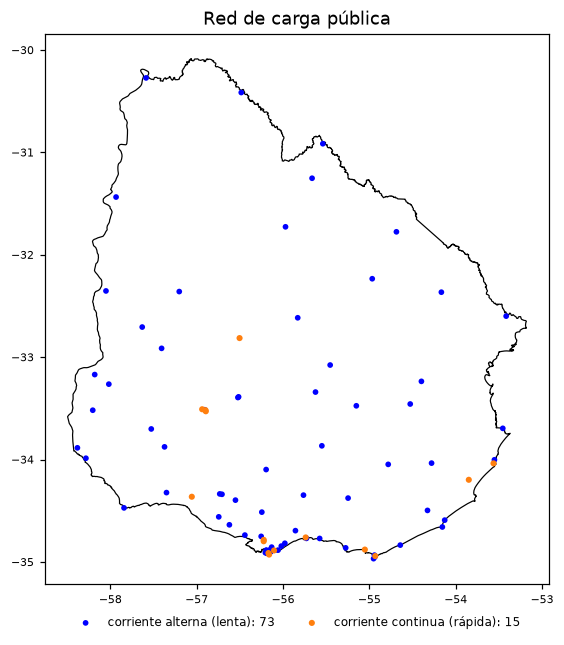

In [54]:
# Borde de Uruguay (geoBoundaries). Se descarga una vez y se guarda en datos/
URL_BORDE = ("https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/main/"
             "releaseData/gbOpen/URY/ADM0/geoBoundaries-URY-ADM0_simplified.geojson")
ARCHIVO_BORDE = DATOS / "borde_uruguay.geojson"
if not ARCHIVO_BORDE.exists():
    descargar(URL_BORDE, ARCHIVO_BORDE)

BORDE = []
for f in json.loads(ARCHIVO_BORDE.read_text(encoding="utf-8"))["features"]:
    g = f["geometry"]
    poligonos = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    BORDE += [np.array(p[0]) for p in poligonos]          # contorno exterior (lon, lat)


def dibujar_red(ax=None, df=cargadores, titulo="Red de carga pública", alpha=1.0):
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 6.5))
    for tipo, et in (("CA", "corriente alterna (lenta)"),
                     ("CC", "corriente continua (rápida)")):
        s = df[df.tipo == tipo]
        ax.scatter(s.lon, s.lat, s=14 if tipo == "CA" else 16, alpha=alpha,
                   color="blue" if tipo == "CA" else "tab:orange",
                   label=f"{et}: {len(s)}", edgecolors="none")
    xlim, ylim = ax.get_xlim(), ax.get_ylim()           # zoom que dan los puntos
    for b in BORDE:
        ax.plot(b[:, 0], b[:, 1], color="black", lw=0.8, zorder=0)
    if xlim[1] - xlim[0] < 3:   # zona chica (< 3° de longitud): se mantiene el zoom
        ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect(1 / math.cos(math.radians(-32.5)))   # que Uruguay no se vea estirado
    ax.set_title(titulo)
    ax.tick_params(labelsize=7)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), borderaxespad=2.2, ncol=2,
              fontsize=8, frameon=False)
    return ax

dibujar_red(); guardar("red_de_carga")

---
## Paso 2 — El vehículo (genérico)

El algoritmo no está atado a un modelo de auto: recibe sus parámetros.

| Símbolo | Significado | Unidad |
|---|---|---|
| $B$ | capacidad de la batería | kWh |
| $\kappa$ | consumo medio | kWh/km |
| $\bar P_{CA}$, $\bar P_{CC}$ | potencia máxima que **admite el auto** en alterna y en continua | kW |
| $b_{\min}$ | reserva mínima que nunca se usa | kWh |

En un cargador $i$ la potencia efectiva es $P_i = \min(p_i, \bar P_{k_i})$: manda el más lento
entre el cargador y el auto.

Abajo hay tres vehículos de ejemplo (chico, mediano y grande). **Para probar con otro auto,
agregalo a la lista con sus datos.**

In [51]:
@dataclass
class Vehiculo:
    nombre: str
    B: float            # kWh
    kappa: float        # kWh/km
    P_CA: float         # kW máximos en alterna
    P_CC: float         # kW máximos en continua
    reserva: float = 0.10   # fracción de B que no se usa (b_min = reserva * B)

    @property
    def b_min(self):
        return self.reserva * self.B

    @property
    def autonomia_km(self):
        # Máximo que puede recorrer con la batería llena sin tocar la reserva
        return (self.B - self.b_min) / self.kappa

    def potencia(self, tipo, kw_cargador):
        # P_i = min(p_i, P_k)
        return min(kw_cargador, self.P_CC if tipo == "CC" else self.P_CA)


VEHICULOS = [
    Vehiculo("chico",   B=40, kappa=0.150, P_CA=7.4, P_CC=50),
    Vehiculo("mediano", B=60, kappa=0.165, P_CA=11,  P_CC=100),
    Vehiculo("grande",  B=80, kappa=0.190, P_CA=11,  P_CC=150),
]

display(pd.DataFrame([{**v.__dict__, "b_min": v.b_min, "autonomía (km)": v.autonomia_km}
                      for v in VEHICULOS]).set_index("nombre"))

,B,kappa,P_CA,P_CC,reserva,b_min,autonomía (km)
nombre,,,,,,,
chico,40,0.15,7.4,50,0.1,4.0,240.00
mediano,60,0.17,11.0,100,0.1,6.0,327.27
grande,80,0.19,11.0,150,0.1,8.0,378.95


---
## Paso 3 — Distancias y tiempos por carretera

Para cada par de puntos $(i, j)$ hacen falta la distancia $d_{ij}$ (km) y el tiempo de manejo
$\tau_{ij}$ (h) **por carretera**. Se calculan con **OSRM** sobre la red vial de
**OpenStreetMap**, pidiendo la *tabla* de distancias en bloques.

- El resultado se guarda en `datos/` y no se vuelve a pedir.
- Si no hay internet o el servicio falla, se usa una **aproximación**: distancia en línea recta
  (fórmula de *haversine*) multiplicada por un factor de desvío, y una velocidad media. Se
  avisa cuando pasa, porque es menos preciso.

También se guarda $\hat d_{ij}$, la distancia **en línea recta**, que usa el voraz para estimar
cuánto falta.

In [55]:
OSRM = "https://router.project-osrm.org/table/v1/driving/"
BLOQUE = 50            # 50 orígenes + 50 destinos = 100 coordenadas por pedido
FACTOR_DESVIO = 1.30   # sólo para la aproximación sin internet
VEL_MEDIA = 75.0       # km/h, sólo para la aproximación sin internet
V_MAX = 110.0          # km/h, velocidad máxima de la red (la usa el voraz)


def haversine(lat, lon):
    # Matriz de distancias en línea recta (km) entre todos los puntos
    la, lo = np.radians(lat), np.radians(lon)
    dla = la[:, None] - la[None, :]
    dlo = lo[:, None] - lo[None, :]
    a = np.sin(dla / 2)**2 + np.cos(la[:, None]) * np.cos(la[None, :]) * np.sin(dlo / 2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def _pedir_bloque(coords, origenes, destinos):
    pts = [coords[k] for k in origenes] + [coords[k] for k in destinos]
    txt = ";".join(f"{lon:.6f},{lat:.6f}" for lat, lon in pts)
    no = len(origenes)
    url = (OSRM + txt + "?annotations=duration,distance"
           + "&sources=" + ";".join(map(str, range(no)))
           + "&destinations=" + ";".join(map(str, range(no, len(pts)))))
    ultimo = None
    for intento in range(3):
        try:
            pedido = urllib.request.Request(url, headers={"User-Agent": "algabo-ucu/1.0"})
            with urllib.request.urlopen(pedido, timeout=60) as r:
                res = json.load(r)
            if res.get("code") == "Ok":
                return res
        except Exception as e:
            ultimo = e
        time.sleep(2 * (intento + 1))
    raise RuntimeError(f"OSRM no respondió: {ultimo}")


def matriz_osrm(lat, lon):
    n = len(lat)
    coords = list(zip(lat, lon))
    D = np.full((n, n), np.nan)
    T = np.full((n, n), np.nan)
    bloques = [list(range(k, min(k + BLOQUE, n))) for k in range(0, n, BLOQUE)]
    total, hechos = len(bloques)**2, 0
    for o in bloques:
        for d in bloques:
            res = _pedir_bloque(coords, o, d)
            dist = np.array(res["distances"], dtype=float)    # metros (None -> nan)
            dur = np.array(res["durations"], dtype=float)     # segundos
            D[np.ix_(o, d)] = dist / 1000.0
            T[np.ix_(o, d)] = dur / 3600.0
            hechos += 1
            print(f"\r  OSRM: bloque {hechos}/{total}", end="")
            time.sleep(1.0)                                    # no saturar el servidor público
    print()
    return D, T


def matrices_viaje(lat, lon, usar_osrm=True):
    # Devuelve D (km por carretera), T (horas de manejo), Dlr (km en línea recta) y la fuente
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    Dlr = haversine(lat, lon)
    clave = hashlib.sha1(np.round(np.c_[lat, lon], 5).tobytes()).hexdigest()[:12]
    cache = DATOS / f"matriz_{clave}.npz"
    if cache.exists():
        z = np.load(cache)
        print(f"Matrices leídas de {cache} (fuente: {z['fuente']})")
        return z["D"], z["T"], Dlr, str(z["fuente"])

    fuente = "aproximación (línea recta)"
    D = Dlr * FACTOR_DESVIO
    T = D / VEL_MEDIA
    if usar_osrm:
        try:
            print(f"Pidiendo a OSRM la tabla de {len(lat)}x{len(lat)} (puede tardar unos minutos)...")
            Do, To = matriz_osrm(lat, lon)
            faltan = np.isnan(Do) | np.isnan(To)
            Do[faltan], To[faltan] = D[faltan], T[faltan]      # pares sin ruta: aproximación
            D, T, fuente = Do, To, "OSRM / OpenStreetMap"
            if faltan.any():
                print(f"  {faltan.sum()} pares sin ruta en OSRM: se completaron con la aproximación")
        except Exception as e:
            print(f"  ATENCIÓN: no se pudo usar OSRM ({e}).")
            print("  Se usa la aproximación en línea recta. Para reintentar, borrá el archivo")
            print(f"  {cache} y volvé a correr la celda.")
    np.fill_diagonal(D, 0.0); np.fill_diagonal(T, 0.0)
    np.savez(cache, D=D, T=T, fuente=fuente)
    print(f"Matrices guardadas en {cache} (fuente: {fuente})")
    return D, T, Dlr, fuente

Se calcula **una sola matriz** con todas las ciudades de las instancias y todos los cargadores.
Las instancias del paso siguiente toman sub-matrices de esta.

In [56]:
CIUDADES = {                       # (lat, lon)
    "Montevideo":     (-34.9058, -56.1913),
    "Punta del Este": (-34.9620, -54.9510),
    "Colonia":        (-34.4710, -57.8440),
    "Chuy":           (-33.6970, -53.4600),
    "Artigas":        (-30.4000, -56.4670),
}
NOMBRES_CIUDADES = list(CIUDADES)

PUNTOS = pd.concat([
    pd.DataFrame([{"nombre": c, "lat": la, "lon": lo, "tipo": "ciudad", "kw": 0.0}
                  for c, (la, lo) in CIUDADES.items()]),
    cargadores[["nombre", "lat", "lon", "tipo", "kw"]],
], ignore_index=True)

D_TOTAL, T_TOTAL, DLR_TOTAL, FUENTE = matrices_viaje(PUNTOS.lat, PUNTOS.lon)
print(f"{len(PUNTOS)} puntos  ·  fuente de distancias: {FUENTE}")

Matrices leídas de datos\matriz_025f05a26ba5.npz (fuente: OSRM / OpenStreetMap)
93 puntos  ·  fuente de distancias: OSRM / OpenStreetMap


**Verificación.** Las matrices tienen sentido físico.

In [58]:
n = len(PUNTOS)
assert D_TOTAL.shape == T_TOTAL.shape == (n, n)
assert np.all(np.diag(D_TOTAL) == 0) and np.all(D_TOTAL >= 0) and np.all(T_TOTAL >= 0)
# OSRM mide desde la calle más cercana a cada punto: en tramos de pocos cientos de metros
# eso puede dar un poco menos que la línea recta. Se tolera hasta 1 km de diferencia.
assert np.all(D_TOTAL + 1.0 >= DLR_TOTAL), "la carretera no puede ser más corta que la línea recta"

i, j = NOMBRES_CIUDADES.index("Montevideo"), NOMBRES_CIUDADES.index("Punta del Este")
print(f"Montevideo → Punta del Este: {D_TOTAL[i, j]:.0f} km por carretera "
      f"({DLR_TOTAL[i, j]:.0f} km en línea recta), {T_TOTAL[i, j]*60:.0f} min de manejo")

AssertionError: la carretera no puede ser más corta que la línea recta

---
## Paso 4 — Instancias

Tres tamaños, como en el informe. Cada instancia toma el origen, el destino y **los cargadores
de una zona** (un rectángulo de latitud y longitud):

| Instancia | Viaje | Zona |
|---|---|---|
| chica | Montevideo → Punta del Este (~130 km) | costa de Montevideo a Maldonado |
| mediana | Colonia → Chuy (~500 km) | franja sur del país |
| grande | Artigas → Montevideo (~600 km) | todo el país |

In [59]:
@dataclass
class Instancia:
    nombre: str
    origen: str
    destino: str
    nodos: list               # índices en PUNTOS; nodos[0] = s, nodos[1] = t
    D: np.ndarray = field(repr=False)
    T: np.ndarray = field(repr=False)
    Dlr: np.ndarray = field(repr=False)
    tipo: np.ndarray = field(repr=False)
    kw: np.ndarray = field(repr=False)

    @property
    def n(self):
        return len(self.nodos)

    def etiqueta(self, k):
        fila = PUNTOS.iloc[self.nodos[k]]
        return fila.nombre if k < 2 else f"{fila.nombre} ({fila.tipo} {fila.kw:g} kW)"


def construir_instancia(nombre, origen, destino, zona=None):
    # zona = (lat_min, lat_max, lon_min, lon_max) o None para todo el país
    s, t = NOMBRES_CIUDADES.index(origen), NOMBRES_CIUDADES.index(destino)
    es_carg = (PUNTOS.tipo != "ciudad").to_numpy().copy()
    if zona:
        la0, la1, lo0, lo1 = zona
        es_carg &= PUNTOS.lat.between(la0, la1).to_numpy() & PUNTOS.lon.between(lo0, lo1).to_numpy()
    nodos = [s, t] + [int(k) for k in np.flatnonzero(es_carg)]
    ix = np.ix_(nodos, nodos)
    return Instancia(nombre, origen, destino, nodos,
                     D_TOTAL[ix], T_TOTAL[ix], DLR_TOTAL[ix],
                     PUNTOS.tipo.to_numpy()[nodos], PUNTOS.kw.to_numpy()[nodos])


INSTANCIAS = [
    construir_instancia("chica",   "Montevideo", "Punta del Este", zona=(-35.1, -34.55, -56.45, -54.80)),
    construir_instancia("mediana", "Colonia",    "Chuy",           zona=(-35.1, -33.40, -58.50, -53.30)),
    construir_instancia("grande",  "Artigas",    "Montevideo",     zona=None),
]

display(pd.DataFrame([{"instancia": I.nombre, "viaje": f"{I.origen} → {I.destino}",
                       "km por carretera": I.D[0, 1], "|V|": I.n,
                       "cargadores CC": int((I.tipo == "CC").sum()),
                       "cargadores CA": int((I.tipo == "CA").sum())}
                      for I in INSTANCIAS]).set_index("instancia"))

,viaje,km por carretera,|V|,cargadores CC,cargadores CA
instancia,,,,,
chica,Montevideo → Punta del Este,134.75,33,8,23
mediana,Colonia → Chuy,511.19,67,14,51
grande,Artigas → Montevideo,616.86,90,15,73


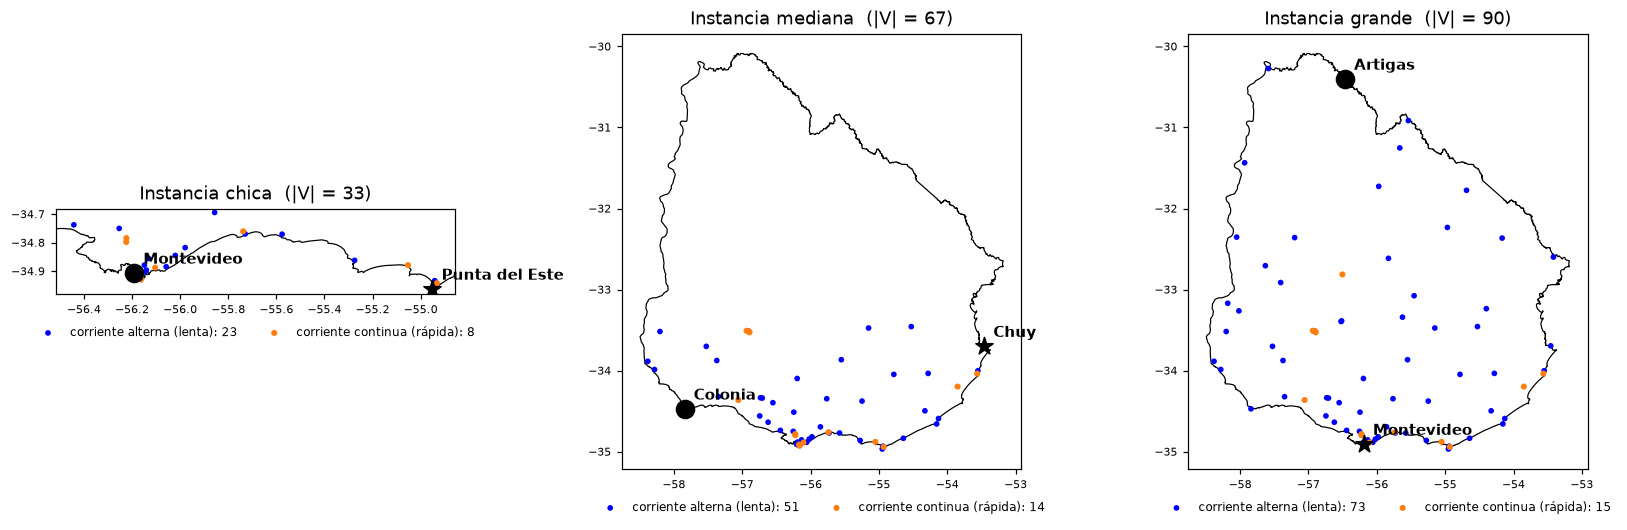

In [60]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, I in zip(axs, INSTANCIAS):
    dibujar_red(ax, PUNTOS.iloc[I.nodos[2:]], titulo=f"Instancia {I.nombre}  (|V| = {I.n})")
    for k, m in ((0, "o"), (1, "*")):
        p = PUNTOS.iloc[I.nodos[k]]
        ax.scatter(p.lon, p.lat, s=140, marker=m, color="black", zorder=5)
        ax.annotate(p.nombre, (p.lon, p.lat), xytext=(6, 6), textcoords="offset points",
                    fontweight="bold")
plt.tight_layout(); guardar("instancias")

---
## Paso 5 — El grafo $G = (V, E)$

$V = \{s, t\} \cup C$. El supuesto central es que **el auto sale con la batería llena y en cada
parada recarga al 100 %**. Entonces, al salir de cualquier punto la batería es siempre $B$, y:

- **Hay arista** $(i, j)$ si y solo si el tramo se puede hacer con la batería llena:
  $e_{ij} = \kappa\, d_{ij} \le B - b_{\min}$.
- **Costo de la arista**: manejar, y si $j$ es un cargador, recargar lo que se gastó:

$$
c_{ij} = \begin{cases} \tau_{ij} + \dfrac{e_{ij}}{P_j} & \text{si } j \in C \\[1ex] \tau_{ij} & \text{si } j = t \end{cases}
$$

No hay aristas que entren a $s$ ni que salgan de $t$.

**Lo que lo hace distinto de un camino mínimo común:** el grafo **depende del vehículo**. Con
otro auto cambian qué aristas existen (autonomía) y cuánto cuesta cada una (consumo y potencia
que admite). Por eso el grafo se construye para cada par (instancia, vehículo).

In [ ]:
@dataclass
class Grafo:
    inst: Instancia
    veh: Vehiculo
    ady: list          
    P: np.ndarray      # potencia efectiva en cada nodo (kW)
    m: int             # |E|
    segundos: float    # tiempo de construcción


def construir_grafo(inst, veh):
    t0 = time.perf_counter()
    n = inst.n
    E = veh.kappa * inst.D                                     # e_ij (kWh)
    P = np.array([veh.potencia(inst.tipo[k], inst.kw[k]) if k >= 2 else np.nan
                  for k in range(n)])
    existe = E <= veh.B - veh.b_min + 1e-9
    np.fill_diagonal(existe, False)
    existe[:, 0] = False          
    existe[1, :] = False          

    costo = inst.T.copy()
    costo[:, 2:] += E[:, 2:] / P[2:]                           

    ady = [[(int(j), float(costo[i, j])) for j in np.flatnonzero(existe[i])] for i in range(n)]
    return Grafo(inst, veh, ady, P, int(existe.sum()), time.perf_counter() - t0)


G = construir_grafo(INSTANCIAS[1], VEHICULOS[1])     # mediana, vehículo mediano
print(f"Instancia {G.inst.nombre}, vehículo {G.veh.nombre}:  |V| = {G.inst.n},  |E| = {G.m}  "
      f"(de {G.inst.n*(G.inst.n-1)} posibles)  ·  construido en {G.segundos*1000:.1f} ms")

Instancia mediana, vehículo mediano:  |V| = 67,  |E| = 3872  (de 4422 posibles)  ·  construido en 4.5 ms


**Verificación.** Ninguna arista supera la autonomía y todos los costos son no negativos (condición de Dijkstra).

In [62]:
for I in INSTANCIAS:
    for v in VEHICULOS:
        g = construir_grafo(I, v)
        for i, vec in enumerate(g.ady):
            for j, c in vec:
                assert v.kappa * I.D[i, j] <= v.B - v.b_min + 1e-6
                assert c >= 0
                assert j != 0 and i != 1
print("Grafo correcto para todas las instancias y vehículos.")

display(pd.DataFrame([[construir_grafo(I, v).m for v in VEHICULOS] for I in INSTANCIAS],
                     index=[I.nombre for I in INSTANCIAS],
                     columns=[f"|E| {v.nombre}" for v in VEHICULOS]))

Grafo correcto para todas las instancias y vehículos.


,|E| chico,|E| mediano,|E| grande
chica,993,993,993
mediana,3231,3872,4026
grande,4062,5425,5965


---
# ⭐ Enfoque 1 — Dijkstra (exacto)

Con la recarga al 100 %, el problema es un **camino mínimo con costos no negativos**, que es
justo lo que resuelve Dijkstra.

1. `dist[s] = 0`, el resto $\infty$. Se mete $s$ en una cola de prioridad (*heap*).
2. Se saca el nodo $u$ de menor `dist`. Si ya estaba cerrado, se ignora.
3. Si $u = t$, se termina: ese es el tiempo óptimo.
4. Para cada arista $(u, v)$: si `dist[u] + c_uv < dist[v]`, se actualiza y se guarda `padre[v] = u`.

**Garantía:** óptimo exacto del modelo. **Complejidad:** $O((|V|+|E|)\log|V|)$.

In [ ]:
@dataclass
class Resultado:
    algoritmo: str
    costo_h: float          
    camino: list            
    expandidos: int        
    segundos: float

    @property
    def factible(self):
        return self.costo_h < inf

    @property
    def paradas(self):
        return max(0, len(self.camino) - 2)


def dijkstra(G):
    t0 = time.perf_counter()
    n = G.inst.n
    dist = [inf] * n
    padre = [-1] * n
    cerrado = [False] * n
    dist[0] = 0.0
    heap = [(0.0, 0)]
    expandidos = 0
    while heap:
        d, u = heapq.heappop(heap)
        if cerrado[u]:
            continue
        cerrado[u] = True
        expandidos += 1
        if u == 1:                                   
            break
        for v, c in G.ady[u]:
            nd = d + c
            if nd < dist[v]:
                dist[v], padre[v] = nd, u
                heapq.heappush(heap, (nd, v))
    camino = []
    if dist[1] < inf:
        k = 1
        while k != -1:
            camino.append(k)
            k = padre[k]
        camino.reverse()
    return Resultado("Dijkstra", dist[1], camino, expandidos, time.perf_counter() - t0)


res_d = dijkstra(G)
print(f"Dijkstra: {res_d.costo_h*60:.0f} min, {res_d.paradas} parada(s), "
      f"{res_d.expandidos} nodos expandidos, {res_d.segundos*1000:.2f} ms")

Dijkstra: 476 min, 2 parada(s), 59 nodos expandidos, 0.44 ms


### Ver la ruta tramo por tramo

`detalle_ruta` arma la tabla de la ruta (manejo y carga de cada tramo) y `verificar_ruta`
**recalcula el costo desde cero** con las fórmulas del modelo y controla que cada tramo sea
factible. Sirven para los dos enfoques.

In [64]:
def detalle_ruta(G, res):
    I, v = G.inst, G.veh
    filas = []
    for a, b in zip(res.camino, res.camino[1:]):
        e = v.kappa * I.D[a, b]
        carga_h = e / G.P[b] if b >= 2 else 0.0
        filas.append({"desde": I.etiqueta(a), "hasta": I.etiqueta(b),
                      "km": I.D[a, b], "manejo (min)": I.T[a, b] * 60,
                      "kWh usados": e, "carga (min)": carga_h * 60,
                      "batería al llegar (%)": 100 * (v.B - e) / v.B})
    df = pd.DataFrame(filas)
    if len(df):
        df.loc["TOTAL"] = df[["km", "manejo (min)", "kWh usados", "carga (min)"]].sum()
        df.loc["TOTAL", ["desde", "hasta", "batería al llegar (%)"]] = ["", "", np.nan]
    return df


def verificar_ruta(G, res, tol=1e-6):
    if not res.factible:
        return True
    I, v = G.inst, G.veh
    assert res.camino[0] == 0 and res.camino[-1] == 1, "la ruta tiene que ir de s a t"
    assert len(set(res.camino)) == len(res.camino), "no se repiten cargadores"
    total = 0.0
    for a, b in zip(res.camino, res.camino[1:]):
        e = v.kappa * I.D[a, b]
        assert e <= v.B - v.b_min + tol, f"tramo {a}->{b} supera la autonomía"
        total += I.T[a, b] + (e / G.P[b] if b >= 2 else 0.0)
    assert abs(total - res.costo_h) < tol, f"costo informado {res.costo_h} != recalculado {total}"
    return True


verificar_ruta(G, res_d)
display(detalle_ruta(G, res_d))

,desde,hasta,km,manejo (min),kWh usados,carga (min),batería al llegar (%)
0,Colonia,OSM 13854073964 (CC 180 kW),174.03,148.28,28.71,17.23,52.14
1,OSM 13854073964 (CC 180 kW),Las Toscas ANCAP (CC 50 kW),50.08,55.09,8.26,9.92,86.23
2,Las Toscas ANCAP (CC 50 kW),Chuy,280.18,245.79,46.23,0.00,22.95
TOTAL,,,504.29,449.16,83.21,27.15,NaN


---
# ⭐ Enfoque 2 — Voraz (heurístico)

Imita cómo planifica un conductor: avanzar hacia el destino eligiendo **el próximo cargador
que parece mejor ahora**, sin volver atrás. Desde la posición actual $u$ (con batería llena):

1. Si $(u, t) \in E$, va directo al destino y termina.
2. Si no, arma los candidatos $R$: cargadores $j$ **no visitados**, con $(u, j) \in E$ y **más
   cerca del destino** que $u$ (en línea recta).
3. Elige el que minimiza
   $$g(j) = c_{uj} + \frac{\hat d_{jt}}{v_{\max}}$$
   (tiempo real de llegar y recargar en $j$ + estimación optimista de lo que falta).
4. Recarga al 100 % en $j$ y vuelve al paso 1.

Si $R$ queda vacío, **no encuentra solución** (aunque exista). No tiene garantía de
optimalidad; su calidad se mide con el *gap* respecto de Dijkstra.

**Complejidad:** $O(|C|^2)$ en el peor caso, $O(k\,|C|)$ en la práctica ($k$ = paradas).

In [ ]:
def voraz(G, v_max=V_MAX):
    t0 = time.perf_counter()
    I = G.inst
    costos = [dict(vec) for vec in G.ady]          
    u, camino, total, evaluados = 0, [0], 0.0, 0
    visitado = {0}
    while True:
        if 1 in costos[u]:                         
            camino.append(1)
            total += costos[u][1]
            break
        mejor, g_mejor = None, inf                 
        for j, c in costos[u].items():
            if j in visitado or I.Dlr[j, 1] >= I.Dlr[u, 1]:
                continue
            evaluados += 1
            g = c + I.Dlr[j, 1] / v_max
            if g < g_mejor:
                mejor, g_mejor = j, g
        if mejor is None:                          
            return Resultado("Voraz", inf, [], evaluados, time.perf_counter() - t0)
        total += costos[u][mejor]                  
        camino.append(mejor)
        visitado.add(mejor)
        u = mejor
    return Resultado("Voraz", total, camino, evaluados, time.perf_counter() - t0)


res_v = voraz(G)
verificar_ruta(G, res_v)
print(f"Voraz:    {res_v.costo_h*60:.0f} min, {res_v.paradas} parada(s), "
      f"{res_v.expandidos} candidatos evaluados, {res_v.segundos*1000:.2f} ms")
print(f"Dijkstra: {res_d.costo_h*60:.0f} min  →  gap = {100*(res_v.costo_h/res_d.costo_h - 1):.1f} %")
display(detalle_ruta(G, res_v))

Voraz:    565 min, 7 parada(s), 313 candidatos evaluados, 0.67 ms
Dijkstra: 476 min  →  gap = 18.5 %


,desde,hasta,km,manejo (min),kWh usados,carga (min),batería al llegar (%)
0,Colonia,Colonia del Sacramento ANCAP (CA 43 kW),0.42,1.05,0.07,0.38,99.88
1,Colonia del Sacramento ANCAP (CA 43 kW),Ecilda Paullier (CC 50 kW),75.36,60.91,12.43,14.92,79.28
2,Ecilda Paullier (CC 50 kW),San José de Mayo ANCAP (CA 43 kW),33.84,30.31,5.58,30.46,90.69
3,San José de Mayo ANCAP (CA 43 kW),Plaza José Gervasio Artigas San José (CA 43 kW),3.99,6.40,0.66,3.59,98.90
4,Plaza José Gervasio Artigas San José (CA 43 kW),UTE Sub Estación Rodríguez (CA 7.4 kW),17.56,15.75,2.90,23.49,95.17
5,UTE Sub Estación Rodríguez (CA 7.4 kW),Canelones ANCAP (CA 22 kW),36.43,31.20,6.01,32.79,89.98
6,Canelones ANCAP (CA 22 kW),Las Toscas ANCAP (CC 50 kW),66.44,54.39,10.96,13.15,81.73
7,Las Toscas ANCAP (CC 50 kW),Chuy,280.18,245.79,46.23,0.00,22.95
TOTAL,,,514.21,445.81,84.84,118.77,NaN


### Las dos rutas en el mapa

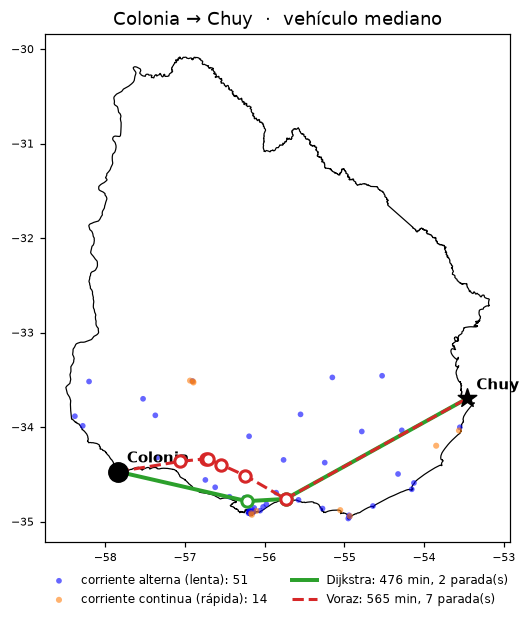

In [66]:
def dibujar_rutas(G, resultados, ax=None):
    I = G.inst
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))
    dibujar_red(ax, PUNTOS.iloc[I.nodos[2:]], alpha=0.6,
                titulo=f"{I.origen} → {I.destino}  ·  vehículo {G.veh.nombre}")
    estilos = {"Dijkstra": dict(color="tab:green", ls="-", lw=2.6),
               "Voraz": dict(color="tab:red", ls="--", lw=2.0)}
    for r in resultados:
        if not r.factible:
            continue
        pts = PUNTOS.iloc[[I.nodos[k] for k in r.camino]]
        linea, = ax.plot(pts.lon, pts.lat, zorder=4, **estilos[r.algoritmo],
                         label=f"{r.algoritmo}: {r.costo_h*60:.0f} min, {r.paradas} parada(s)")
        ax.scatter(pts.lon[1:-1], pts.lat[1:-1], s=55, facecolors="white",
                   edgecolors=linea.get_color(), linewidths=2, zorder=5)
    for k, m in ((0, "o"), (1, "*")):
        p = PUNTOS.iloc[I.nodos[k]]
        ax.scatter(p.lon, p.lat, s=160, marker=m, color="black", zorder=6)
        ax.annotate(p.nombre, (p.lon, p.lat), xytext=(6, 6), textcoords="offset points",
                    fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), borderaxespad=2.2,
              ncol=2, fontsize=8, frameon=False)
    return ax

dibujar_rutas(G, [res_d, res_v]); guardar("ruta_ejemplo")

---
## Paso 8 — Experimentos y comparación

Se cruzan las **3 instancias** con los **3 vehículos** y se corren los dos enfoques. Se miden
tres ejes, como pide la consigna:

- **Calidad:** tiempo de viaje y *gap* del voraz, $\text{gap} = 100\,(T_{\text{voraz}} - T^*)/T^*$.
- **Tiempo de ejecución:** como los dos algoritmos son **deterministas**, el resultado de cada
  corrida es siempre el mismo; lo que varía es el tiempo de cómputo, así que cada uno se corre
  `REPETICIONES` veces y se informa media y desviación estándar.
- **Escalabilidad:** cómo crece el tiempo con $|V|$ y $|E|$.

In [67]:
REPETICIONES = 10


def medir(fn, G, reps=REPETICIONES):
    res = [fn(G) for _ in range(reps)]
    tiempos = np.array([r.segundos for r in res]) * 1000
    return res[0], tiempos.mean(), tiempos.std(ddof=1)


filas, rutas = [], {}
for I in INSTANCIAS:
    for v in VEHICULOS:
        g = construir_grafo(I, v)
        rd, td, sd = medir(dijkstra, g)
        rv, tv, sv = medir(voraz, g)
        verificar_ruta(g, rd); verificar_ruta(g, rv)
        rutas[(I.nombre, v.nombre)] = (g, rd, rv)
        gap = 100 * (rv.costo_h / rd.costo_h - 1) if rd.factible and rv.factible else np.nan
        for r, tm, ts in ((rd, td, sd), (rv, tv, sv)):
            filas.append({"instancia": I.nombre, "vehículo": v.nombre, "|V|": I.n, "|E|": g.m,
                          "enfoque": r.algoritmo,
                          "tiempo viaje (h)": r.costo_h if r.factible else np.nan,
                          "paradas": r.paradas if r.factible else np.nan,
                          "gap (%)": 0.0 if r.algoritmo == "Dijkstra" and r.factible else
                                     (gap if r.algoritmo == "Voraz" else np.nan),
                          "expandidos": r.expandidos,
                          "cómputo media (ms)": tm, "cómputo DE (ms)": ts})

resultados = pd.DataFrame(filas)
display(resultados.set_index(["instancia", "vehículo", "enfoque"]))

|V|   |E|  tiempo viaje (h)  paradas  gap (%)  \
instancia vehículo enfoque                                                   
chica     chico    Dijkstra   33   993              2.33        0     0.00   
                   Voraz      33   993              2.33        0     0.00   
          mediano  Dijkstra   33   993              2.33        0     0.00   
                   Voraz      33   993              2.33        0     0.00   
          grande   Dijkstra   33   993              2.33        0     0.00   
                   Voraz      33   993              2.33        0     0.00   
mediana   chico    Dijkstra   67  3231              8.30        2     0.00   
                   Voraz      67  3231             11.11       14    33.85   
          mediano  Dijkstra   67  3872              7.94        2     0.00   
                   Voraz      67  3872              9.41        7    18.53   
          grande   Dijkstra   67  4026              7.59        1     0.00   
                   Voraz      67  4026              8.61        5    13.43   
grande    chico    Dijkstra   90  4062             12.58        4     0.00   
                   Voraz      90  4062             13.17        5     4.68   
          mediano  Dijkstra   90  5425             10.60        2     0.00   
                   Voraz      90  5425             12.15        5    14.66   
          grande   Dijkstra   90  5965              9.35        1     0.00   
                   Voraz      90  5965             12.73        5    36.23   

                             expandidos  cómputo media (ms)  cómputo DE (ms)  
instancia vehículo enfoque                                                    
chica     chico    Dijkstra          27                0.04         1.08e-02  
                   Voraz              0                0.03         7.07e-03  
          mediano  Dijkstra          27                0.05         3.02e-03  
                   Voraz              0                0.03         5.04e-03  
          grande   Dijkstra          27                0.10         2.18e-02  
                   Voraz              0                0.05         6.27e-03  
mediana   chico    Dijkstra          59                0.36         8.43e-02  
                   Voraz            426                0.44         5.72e-02  
          mediano  Dijkstra          59                0.32         2.50e-02  
                   Voraz            313                0.39         8.12e-02  
          grande   Dijkstra          57                0.23         9.19e-02  
                   Voraz            257                0.19         1.13e-02  
grande    chico    Dijkstra          24                0.05         5.33e-03  
                   Voraz             41                0.11         1.14e-02  
          mediano  Dijkstra          19                0.05         3.02e-03  
                   Voraz             62                0.18         8.92e-02  
          grande   Dijkstra          16                0.08         8.15e-03  
                   Voraz             99                0.24         1.49e-02

**Verificación.** Dijkstra es exacto, así que el voraz nunca puede ganarle.

In [68]:
for (inst, veh), (g, rd, rv) in rutas.items():
    if rv.factible:
        assert rd.factible and rd.costo_h <= rv.costo_h + 1e-9, (inst, veh)
    if not rd.factible:
        assert not rv.factible, "si no existe ruta, el voraz tampoco puede encontrarla"
sin_sol = [(i, v) for (i, v), (_, rd, rv) in rutas.items() if rd.factible and not rv.factible]
print("Correcto: Dijkstra ≤ voraz en todos los casos.")
print("Casos donde el voraz no encontró ruta aunque existía:", sin_sol or "ninguno")

Correcto: Dijkstra ≤ voraz en todos los casos.
Casos donde el voraz no encontró ruta aunque existía: ninguno


### Calidad: tiempo de viaje y *gap*

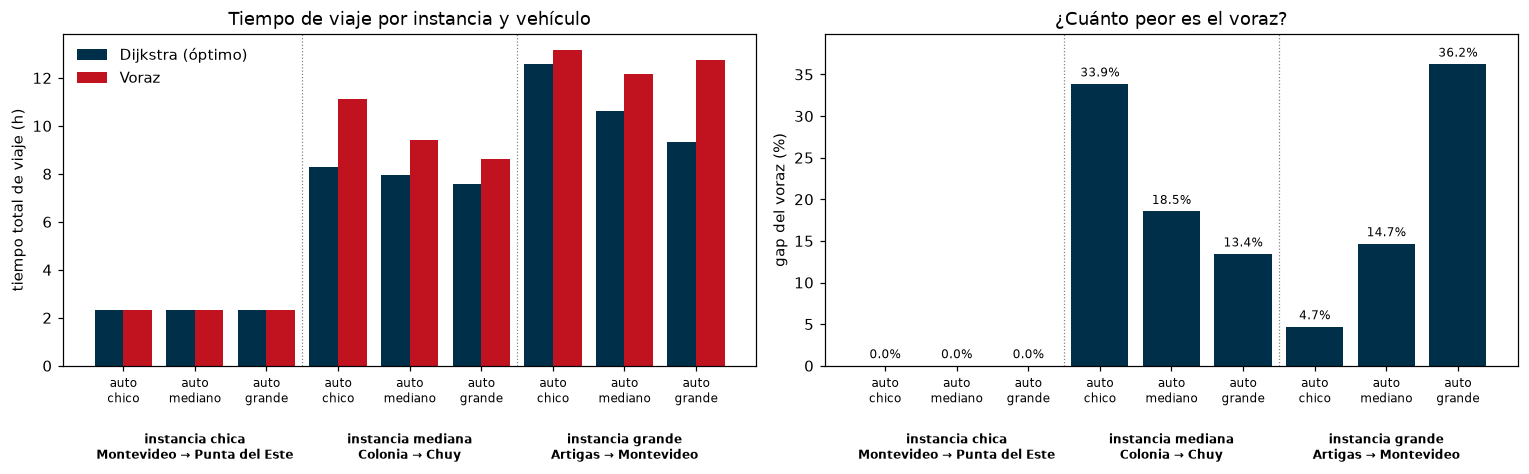

In [70]:
piv = resultados.pivot_table(index=["instancia", "vehículo"], columns="enfoque",
                             values="tiempo viaje (h)", sort=False)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))

x = np.arange(len(piv))
axs[0].bar(x - 0.2, piv["Dijkstra"], 0.4, label="Dijkstra (óptimo)")
axs[0].bar(x + 0.2, piv["Voraz"], 0.4, label="Voraz")
axs[0].set_ylabel("tiempo total de viaje (h)"); axs[0].legend(frameon=False)
axs[0].set_title("Tiempo de viaje por instancia y vehículo")

gaps = resultados[resultados.enfoque == "Voraz"].set_index(["instancia", "vehículo"])["gap (%)"]
axs[1].bar(x, gaps.reindex(piv.index).fillna(0))
for k, gval in enumerate(gaps.reindex(piv.index)):
    axs[1].annotate("sin\nsolución" if np.isnan(gval) else f"{gval:.1f}%", (k, 0 if np.isnan(gval) else gval),
                    ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
axs[1].set_ylabel("gap del voraz (%)"); axs[1].set_title("¿Cuánto peor es el voraz?")
axs[1].margins(y=0.1)   # lugar arriba para el número de la barra más alta

# Eje x: cada barra es un auto; debajo, la instancia (el viaje) que agrupa a esos tres autos
instancia_de = piv.index.get_level_values(0)
for ax in axs:
    ax.set_xticks(x, [f"auto\n{v}" for _, v in piv.index], fontsize=8)
    for I in INSTANCIAS:
        pos = x[instancia_de == I.nombre]
        ax.text(pos.mean(), -0.2, f"instancia {I.nombre}\n{I.origen} → {I.destino}",
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=8, fontweight="bold")
        if pos.max() < x.max():
            ax.axvline(pos.max() + 0.5, color="gray", lw=0.8, ls=":")   # separa instancias
plt.tight_layout(); guardar("calidad")

### Tiempo de ejecución y escalabilidad

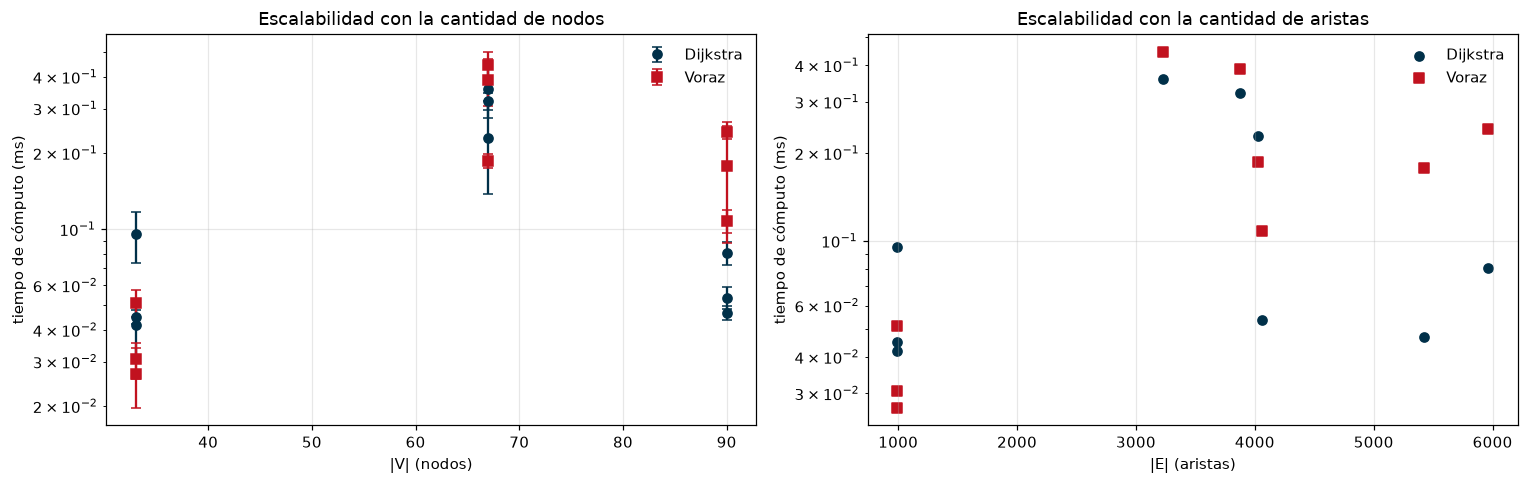

In [71]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for enf, m in (("Dijkstra", "o"), ("Voraz", "s")):
    s = resultados[resultados.enfoque == enf]
    axs[0].errorbar(s["|V|"], s["cómputo media (ms)"], yerr=s["cómputo DE (ms)"],
                    fmt=m, label=enf, capsize=3)
    axs[1].scatter(s["|E|"], s["cómputo media (ms)"], marker=m, label=enf)
for ax, xl in zip(axs, ["|V| (nodos)", "|E| (aristas)"]):
    ax.set_xlabel(xl); ax.set_ylabel("tiempo de cómputo (ms)")
    ax.set_yscale("log"); ax.legend(frameon=False); ax.grid(alpha=0.3)
axs[0].set_title("Escalabilidad con la cantidad de nodos")
axs[1].set_title("Escalabilidad con la cantidad de aristas")
plt.tight_layout(); guardar("escalabilidad")

### Todas las rutas

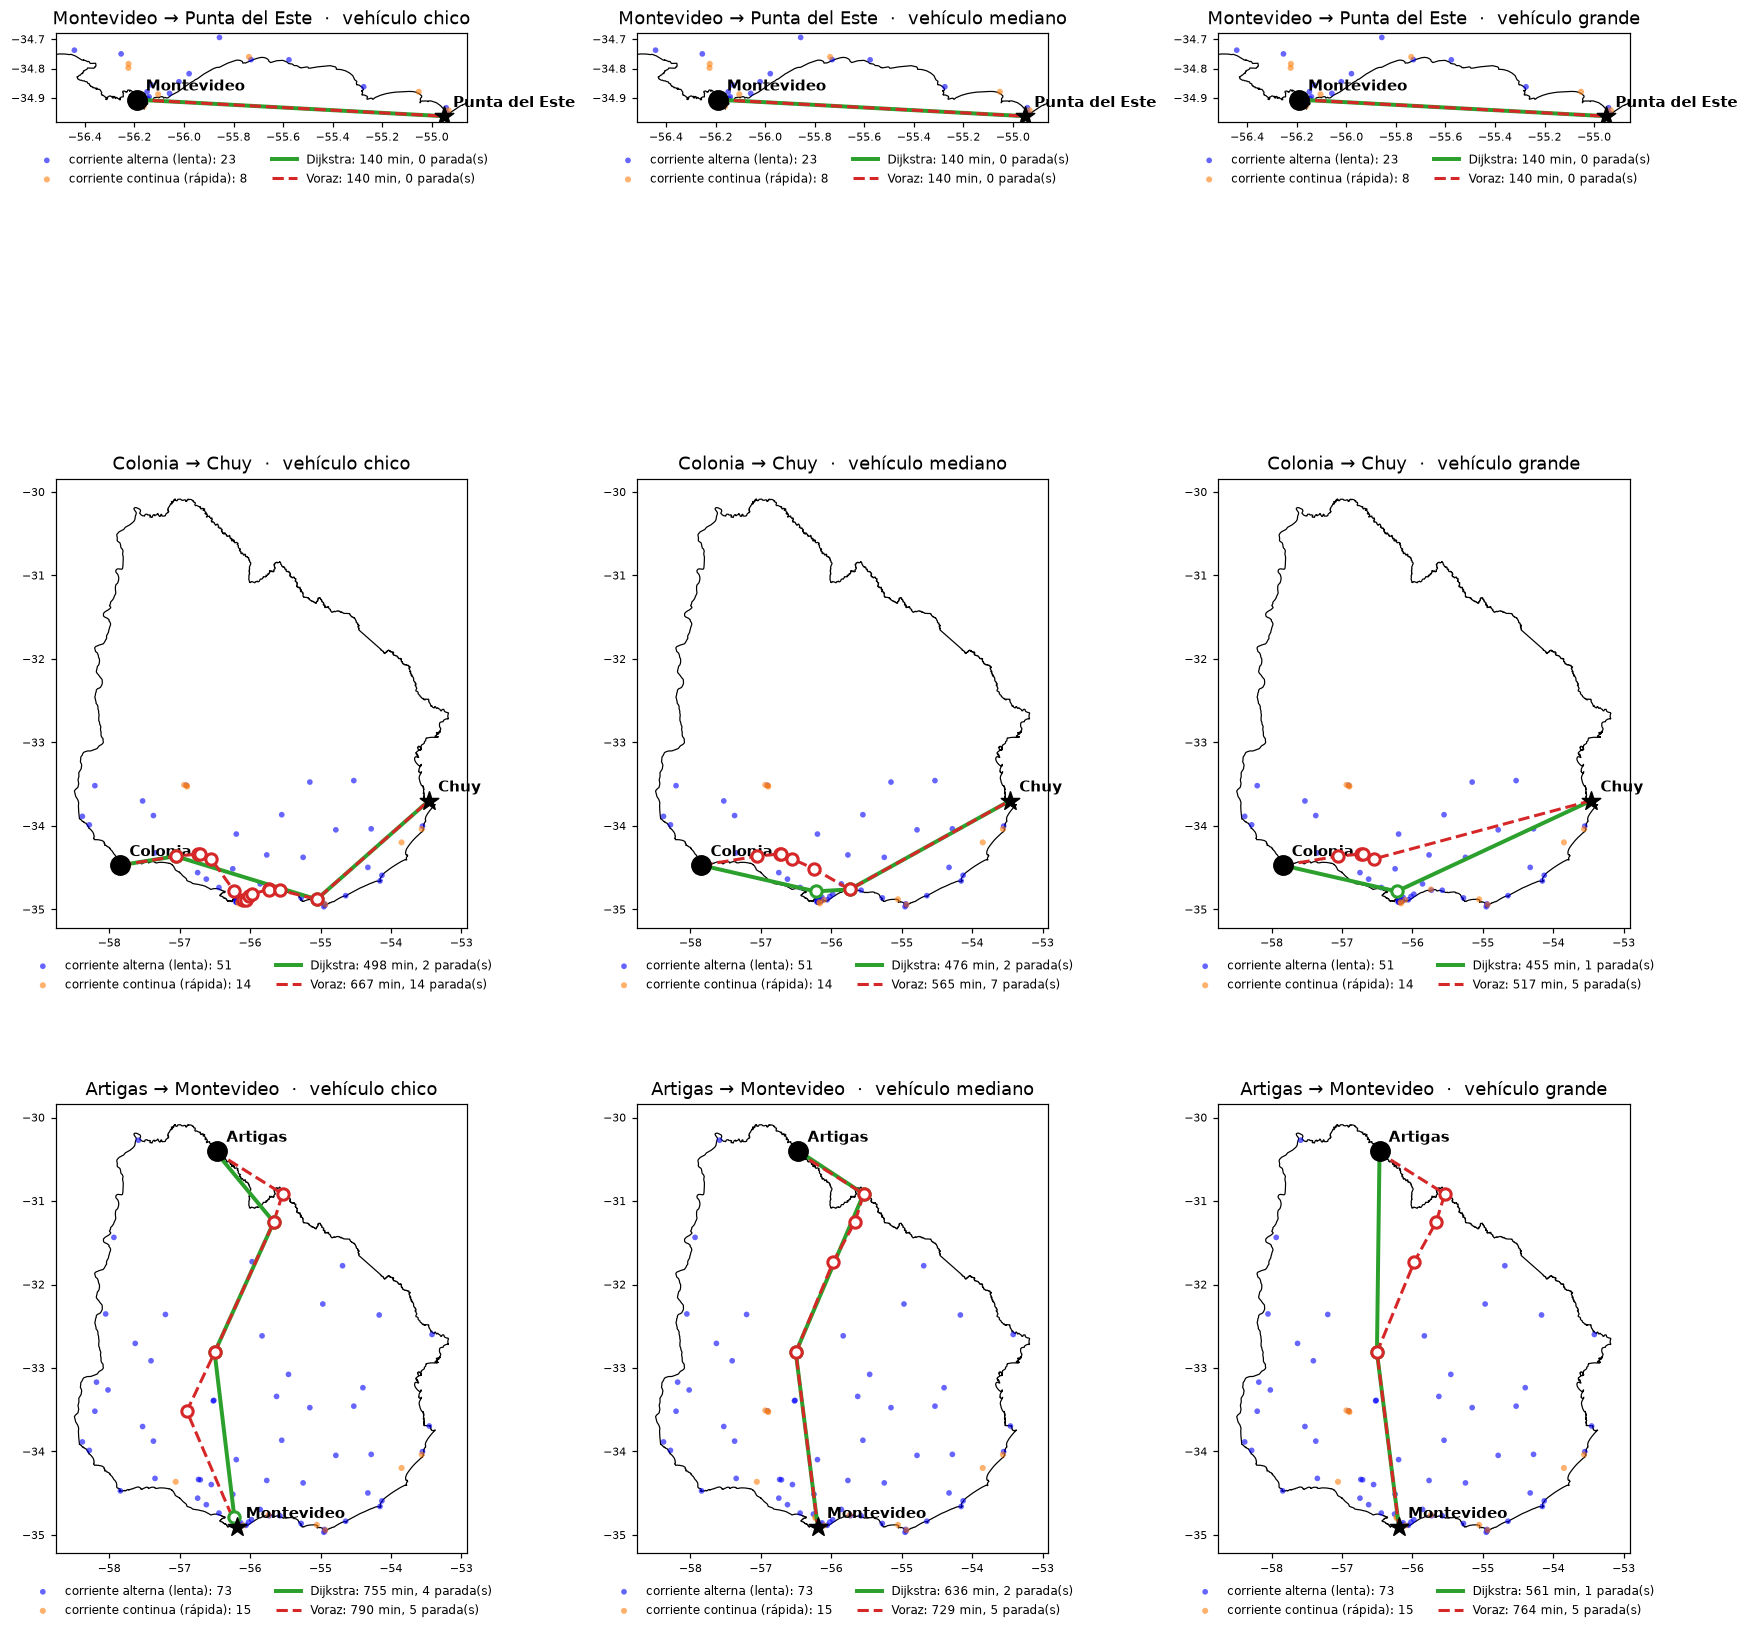

In [72]:
fig, axs = plt.subplots(len(INSTANCIAS), len(VEHICULOS), figsize=(16, 17))
for fila, I in zip(axs, INSTANCIAS):
    for ax, v in zip(fila, VEHICULOS):
        g, rd, rv = rutas[(I.nombre, v.nombre)]
        dibujar_rutas(g, [rd, rv], ax=ax)
plt.tight_layout(); guardar("todas_las_rutas")